# Neural Network Classification with PyTorch  

Book Version:https://www.learnpytorch.io/02_pytorch_classification   
Video Version:https://www.youtube.com/watch?v=V_xro1bcAuA&t=30721s

Classification is a problem of predicting whether something is one thing or another (there can be multiple
things as the options).  

We have basically three types of classification types:  

 - Binary classification

 - Multiclass classification

 - Multilabel classification

## 1.Make classification data and get it ready

In [127]:
import sklearn
from sklearn.datasets import make_circles

# Make 1000 samples
n_samples = 1000

# Create circles
X, y = make_circles(
    n_samples,
    noise=0.03,
    random_state=42
)

`make_circles()` is a toy dataset generating function used for classification tasks  

learn more about `sklearn`'s sample generation functions - https://scikit-learn.org/stable/datasets/sample_generators.html

In [128]:
len(X), len(y)

(1000, 1000)

In [129]:
print(f"First 5 samples of X:\n {X[:5]}")
print(f"First 5 sample of y:\n {y[:5]}")

First 5 samples of X:
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 sample of y:
 [1 1 1 1 0]


In [130]:
# Make DataFrame of circle data
import pandas as pd
circles = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    "label": y
})

circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


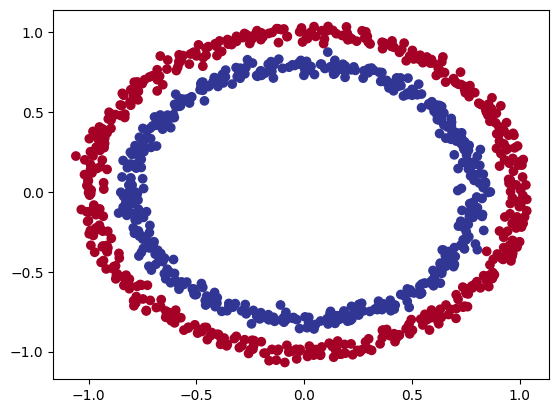

In [131]:
# Visualize, visualize, visualize
import matplotlib.pyplot as plt
plt.scatter(
    x=X[:, 0],
    y=X[:, 1],
    c=y,
    cmap=plt.cm.RdYlBu
)

Note: The data we're working with is often referred to as a toy dataset, a dataset that is small enough to experiment but still sizeable enough to practice the fundamentals.

### 1.1 Check input and output shapes

In [132]:
X.shape, y.shape

((1000, 2), (1000,))

In [133]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]], shape=(1000, 2))

In [134]:
# View the first example of features and labels
X_sample = X[0]
y_sample = y[0]
print(f"Values for one sample of X: {X_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {X_sample.shape} and the same for y: {y_sample.shape}")

Values for one sample of X: [0.75424625 0.23148074] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


### 1.2 Turn data into tensors and create train and test splits


In [135]:
import torch
torch.__version__

'2.14.1+cpu'

In [136]:
type(X)

numpy.ndarray

In [137]:
# Turn data into tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [138]:
type(X), X.dtype, y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [139]:
torch.manual_seed(42)

In [140]:
# Split data into training and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 0.2 = 20% of data will be test & 80% will be train
    random_state=42
)

In [141]:
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

In [142]:
n_samples

1000

## 2.Building a model

Let's build a model to classify our blue and red dots

To do so, we want to:
1. Setup device agonistic code so our code will run on an accelerator (GPU) if there is one  
2. Construct a model (by subclassing `nn.Module`)
3. Define a loss function and optimizer
4. Create a training and test loop


In [143]:
# Import PyTorch and nn
import torch
from torch import nn

# Make device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [144]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

Now we've setup device agnostic code, let's create a model that:

1. Subclass `nn.Module` (almost all model in PyTorch subclass `nn.Module`)
2. Create 2`nn.Linear()` layers that are capable of handling the shapes of our data
3. Defines a `forward()` method that outlines the forward pass(or forward computation) of the model
4. Instatiate an instance of our model class and send it to the target `device`

In [145]:
# 1. Construct a model that subclass nn.Module
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    # 2. Create 2 nn.Linear layers capable of handling the shapes of our data
    self.layer_1 = nn.Linear(in_features=2, out_features=128)
    self.layer_2 = nn.ReLU()
    self.layer_3 = nn.Linear(in_features=128, out_features=256)
    self.layer_4 = nn.ReLU()
    self.layer_5 = nn.Linear(in_features=256, out_features=1)

  # 3. Define a forward() method that outlines the forward pass
  def forward(self, x):
    return self.layer_5(self.layer_4(self.layer_3(self.layer_2(self.layer_1(x)))))

# 4. Instantiate an instance of our model class and send it to the target device
model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=128, bias=True)
  (layer_2): ReLU()
  (layer_3): Linear(in_features=128, out_features=256, bias=True)
  (layer_4): ReLU()
  (layer_5): Linear(in_features=256, out_features=1, bias=True)
)

In [146]:
# Let's replicate the model above using nn.Sequential()
# model_0 = nn.Sequential(
#     nn.Linear(in_features=2, out_features=5),
#     nn.Linear(in_features=5, out_features=1)
# ).to(device)
# model_0

In [147]:
# Make predictions with the model
with torch.inference_mode():
  untrained_preds = model_0(X_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[-0.0340],
        [ 0.0065],
        [-0.0325],
        [-0.0035],
        [-0.0432],
        [-0.0712],
        [-0.0457],
        [-0.0772],
        [-0.0321],
        [ 0.0101]])

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


### 2.1 Setup loss function and optimizer

Which loss function or optimizer should you use?  

Again... this is a problem specific.  

For example for regression you might want MAE or MSE (mean absolute erro or mean squared error).  

For classification you might want binary cross entropy or categorical cross entropy(cross entropy).  

As a reminder, the loss function measures how *wrong* your models predictions are.  

And for optimizers, two of the most common and useful are SGD and Adam, however PyTorch has many built-in options.

- For some common choices of loss functions and optimizers - https://www.learnpytorch.io/01_pytorch_workflow/

- For the loss function we're going to use `torch.nn.BCEWithLogitsLoss()`, for more on what binary cross entropy (BCE) is, check out this article - https://medium.com/data-science/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a  

- For a definition on what a logit is in deep learning - https://forge.coreweave.com/wandb/amanarora/Written-Reports/reports/Understanding-Logits-Sigmoid-Softmax-and-Cross-Entropy-Loss-in-Deep-Learning--Vmlldzo0NDMzNTU3

- For different optimizers see `torch.optim`


In [148]:
# Setup the loss function
loss_fn = nn.BCEWithLogitsLoss()  # logit：sigmoid activation function built in

optimizer = torch.optim.Adam(
    params=model_0.parameters(),
    lr=0.01
)

In [149]:
# Calculate accuracy - out of 100 examples, what percentage does our model get right？
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct/len(y_pred)) * 100
  return acc

In [150]:
# So what is torch.eq() ?
import torch

x = torch.tensor([[1,2],[3,4]])
y = torch.tensor([[1,2],[3,4]])
z = torch.tensor([[1,2],[1,2]])

print(torch.eq(x,y))
print(torch.eq(x,z))

tensor([[True, True],
        [True, True]])
tensor([[ True,  True],
        [False, False]])


## 3.Train model

Training loop:  

- forward pass
- calculate the loss
- optimtizer zero grad
- Loss backward
- optimizer step

### 3.1 Going from raw logits -> prediction probabilities -> prediction labels

Our model outputs are going to be raw **logits**

We can convert these **logits** into **prediction probabilities** by passing them to some kind of activation function (e.g. <mark>sigmoid</mark> for binary classification and <mark>softmax</mark> for multicass classification)  

Then we can convert our model's prediction probabilities to **prediction** labels by either rounding them or taking the `argmax()`



In [151]:
# View the first 5 outputs of the forwaed pass on the test data
model_0.eval()
with torch.inference_mode():
  y_logits = model_0(X_test.to(device))[:5]
y_logits

tensor([[-0.0340],
        [ 0.0065],
        [-0.0325],
        [-0.0035],
        [-0.0432]])

In [152]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [153]:
# Use the sigmoid activation function on our model logits to turn them into prdiction_probabilities
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.4915],
        [0.5016],
        [0.4919],
        [0.4991],
        [0.4892]])

For our prediction probability values, we need to perform a range-style rounding on them:
- `y_pred_probs` >= 0.5, `y=1` (class 1)
- `y_pred_probs` < 0.5, `y=0` (class 0)

In [154]:
# Find the predicted labels
y_preds = torch.round(y_pred_probs)

# In full
y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))

# Check for equality
print(torch.eq(y_preds.squeeze(),y_pred_labels.squeeze()))

# Get rid of extra dimension
y_preds.squeeze()

tensor([True, True, True, True, True])


tensor([0., 1., 0., 0., 0.])

### 3.2 Building a training and testing loop

In [155]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set the number of epochs
epochs = 100

# Put data to target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Build training and evaluation loop
for epoch in range(epochs):
  model_0.train()

  # Do the forward pass
  y_logits = model_0(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  # Caculate the loss
  loss = loss_fn(y_logits, y_train)
  acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

  # optimizer zero grad
  optimizer.zero_grad()

  # loss backward
  loss.backward()

  # optimizer step~ step~ step~
  optimizer.step()

  # Testing
  model_0.eval()
  with torch.inference_mode():
    # 1. Forward pass
    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    # 2. Calculate test loss/acc
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

  # Print out what's happenin'
  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69661, Accuracy: 37.62% | Test loss: 0.68206, Test acc: 50.00%
Epoch: 10 | Loss: 0.36787, Accuracy: 99.12% | Test loss: 0.37034, Test acc: 97.00%
Epoch: 20 | Loss: 0.04701, Accuracy: 100.00% | Test loss: 0.05964, Test acc: 100.00%
Epoch: 30 | Loss: 0.00723, Accuracy: 100.00% | Test loss: 0.01490, Test acc: 100.00%
Epoch: 40 | Loss: 0.00244, Accuracy: 100.00% | Test loss: 0.00853, Test acc: 100.00%
Epoch: 50 | Loss: 0.00151, Accuracy: 100.00% | Test loss: 0.00710, Test acc: 100.00%
Epoch: 60 | Loss: 0.00114, Accuracy: 100.00% | Test loss: 0.00575, Test acc: 100.00%
Epoch: 70 | Loss: 0.00095, Accuracy: 100.00% | Test loss: 0.00508, Test acc: 100.00%
Epoch: 80 | Loss: 0.00084, Accuracy: 100.00% | Test loss: 0.00453, Test acc: 100.00%
Epoch: 90 | Loss: 0.00077, Accuracy: 100.00% | Test loss: 0.00416, Test acc: 100.00%


## 4.Make predictions and evaluate the model  

From the metrics it looks loke our model isn't  learning anything...  

So to inspect it let's make some predictions and make them visual!  

In other words, "Visualize! Visualize! Visualize!"  

To do so, we're going to import a function called `plot_decision_boundary()` - https://github.com/mrdbourke/pytorch-deep-learning/blob/main/helper_functions.py

In [156]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if it's not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions,py already exists, skipping download")
else:
  print('Download helper_functions.py')
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open("helper_function.py","wb") as f:
    f.write(request.content)

from helper_function import plot_predictions, plot_decision_boundary

Download helper_functions.py


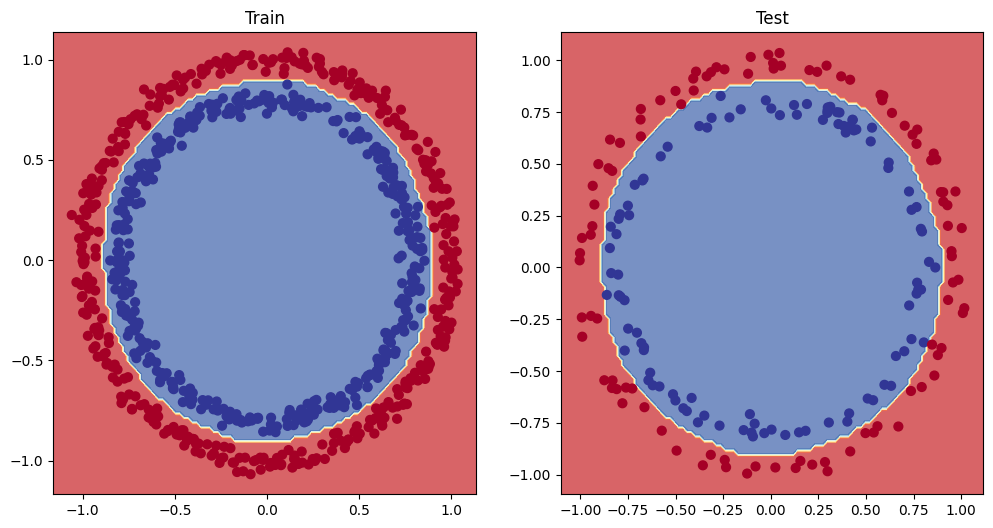

In [157]:
# Plot decision boundary of the model
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0,X_test,y_test)

## 5.Improving a model (from a model perspective)

- Add more layers - give the model more chances to learn about patterns in the data
- Add more hidden units - go from 5 hidden units to 10 hidden units
- Fit for longer
- Changing the activation functions
- Change the learning rate
- Change the loss function  

These options are all from a model's perspective because they deal directly with the model, rather than the data.  

And because these options are all values we( as machine learning engineers and data scientists) can change, they are called hyperparameters.

### 5.1 Preparing data to see if our model can fit a straight line   
One way to troubleshoot to a larger problem is to test out a smaller problem.  

In [158]:
# Create some data (same as notebook 01)
weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.01

# Create data
X_regression = torch.arange(start, end, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias # linear regression formula

# Check the data
print(len(X_regression))
X_regression[:5], y_regression[:5]


100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [159]:
# Create train and test splits
train_split = int(0.8 * len(X_regression)) # 80% of data used for training set
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

# Check the lengths of each split
print(len(X_train_regression),
    len(y_train_regression),
    len(X_test_regression),
    len(y_test_regression))

80 80 20 20


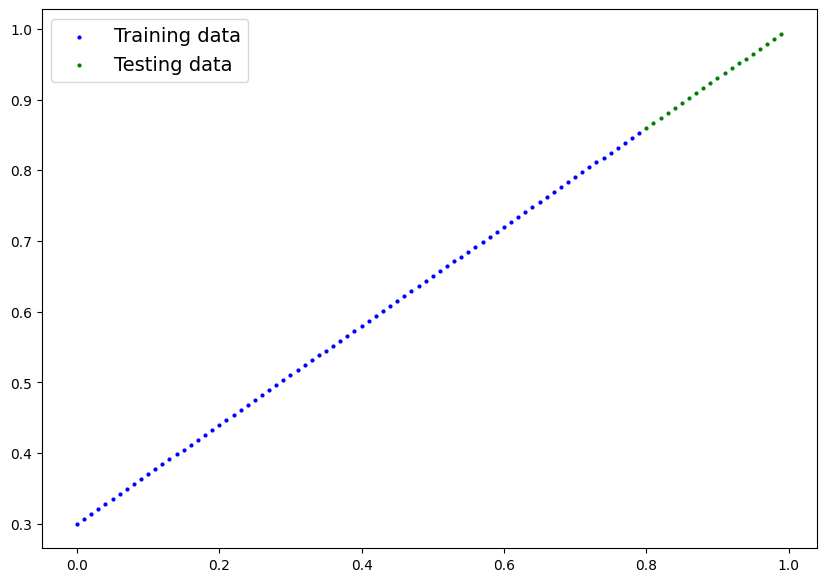

In [160]:
plot_predictions(train_data=X_train_regression,
    train_labels=y_train_regression,
    test_data=X_test_regression,
    test_labels=y_test_regression
);

### 5.2 Adjusting `model_0` to fit a straight line

In [161]:
# Same architecture as model_1 (but using nn.Sequential)
model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [162]:
# Loss and optimizer
loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.1)

In [163]:
# Train the model
torch.manual_seed(42)

# Set the number of epochs
epochs = 100

# Put data to target device
X_train_regression, y_train_regression = X_train_regression.to(device), y_train_regression.to(device)
X_test_regression, y_test_regression = X_test_regression.to(device), y_test_regression.to(device)

for epoch in range(epochs):
    ### Training
    # 1. Forward pass
    y_pred = model_2(X_train_regression)

    # 2. Calculate loss (no accuracy since it's a regression problem, not classification)
    loss = loss_fn(y_pred, y_train_regression)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_2.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_pred = model_2(X_test_regression)
      # 2. Calculate the loss
      test_loss = loss_fn(test_pred, y_test_regression)

    # Print out what's happening
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Train loss: {loss:.5f}, Test loss: {test_loss:.5f}")

Epoch: 0 | Train loss: 0.75986, Test loss: 0.52976
Epoch: 10 | Train loss: 0.11196, Test loss: 0.24699
Epoch: 20 | Train loss: 0.05319, Test loss: 0.11449
Epoch: 30 | Train loss: 0.02070, Test loss: 0.06065
Epoch: 40 | Train loss: 0.03301, Test loss: 0.01795
Epoch: 50 | Train loss: 0.01672, Test loss: 0.03263
Epoch: 60 | Train loss: 0.05869, Test loss: 0.06425
Epoch: 70 | Train loss: 0.04706, Test loss: 0.03128
Epoch: 80 | Train loss: 0.02889, Test loss: 0.00259
Epoch: 90 | Train loss: 0.03339, Test loss: 0.02599


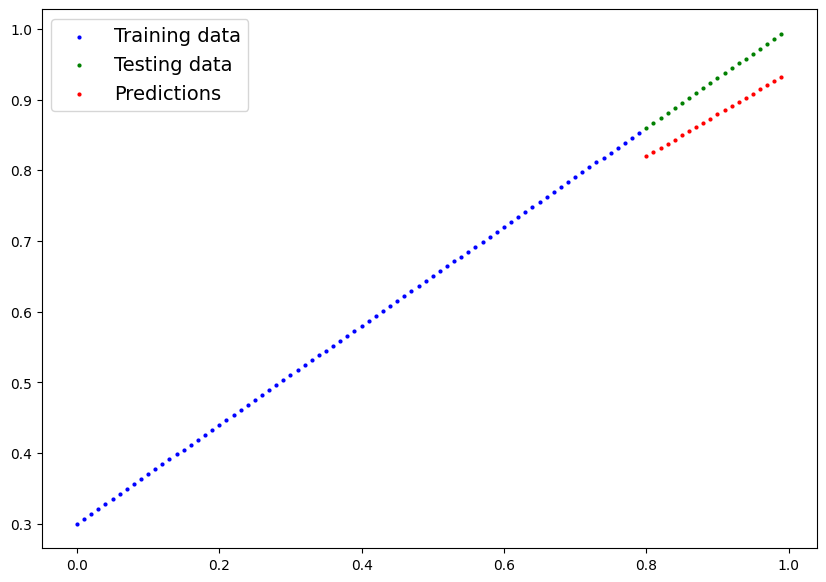

In [164]:
# Turn on evaluation mode
model_2.eval()

# Make predictions (inference)
with torch.inference_mode():
    y_preds = model_2(X_test_regression)

# Plot data and predictions with data on the CPU (matplotlib can't handle data on the GPU)
# (try removing .cpu() from one of the below and see what happens)
plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_preds.cpu());

## 6.The missing piece:non-linearity



### 6.1 Recreating non-linear data( red and blue circles)

First, let's reccreate the data to start off fresh. We'll use the same setup as before.


In [165]:
import torch
import torch.nn as nn

In [166]:
device = "cuda" if torch.cuda.is_available() else "cpu"

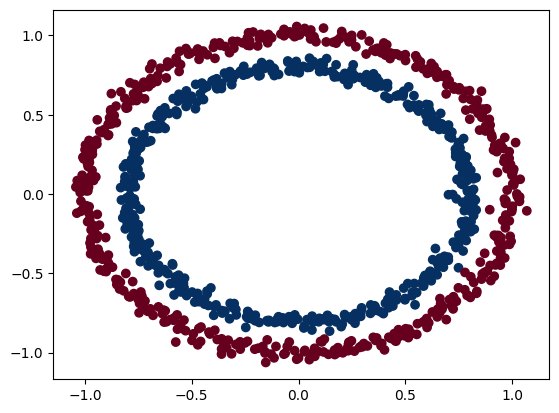

In [167]:
# Make and plot data
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(
    n_samples=1000,
    noise=0.03,
    random_state=24,
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu);

In [168]:
# Convert to tensors and split into train and test data
import torch
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### 6.2 Building a model with non-linearity

- Linear = straight linear lines
- Non-Linear = non-straight lines  

Artificial neural networks are a large combination of linear (straight) and non-linear (non-straight) functions which are potentially able to find patterns in data.

In [169]:
# Build a model with non-linear activation functions
from torch import nn
class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.relu = nn.ReLU()
    self.layer_3 = nn.Linear(in_features=10, out_features=1)


  def forward(self, x):
    return self.layer_3(self.relu(self.layer_2(self.layer_1(x))))

model_3 = CircleModelV2().to(device)

In [170]:
# Setup loss and optimizer
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    model_3.parameters(),
    lr=0.1
)

### 6.3 Training a model with non-linearilty

In [171]:
# Random seed
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Put all data on traget device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Epoch
epochs = 3000

# Training loop
for epoch in range(epochs):
  model_3.train()

  y_logits = model_3(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  train_loss = loss_fn(y_logits, y_train)
  train_acc = accuracy_fn(
      y_true=y_train,
      y_pred=y_pred
  )

  optimizer.zero_grad()

  train_loss.backward()

  optimizer.step()

  # Testing
  model_3.eval()
  with torch.inference_mode():
    test_logits = model_3(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(
        y_true=y_test,
        y_pred=test_pred
    )

  if epoch % 100 == 0:
     print(f"Epoch: {epoch} | Loss: {train_loss:.5f}, Accuracy: {train_acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69754, Accuracy: 49.88% | Test Loss: 0.70254, Test Accuracy: 51.00%
Epoch: 100 | Loss: 0.69271, Accuracy: 56.88% | Test Loss: 0.69521, Test Accuracy: 48.50%
Epoch: 200 | Loss: 0.69050, Accuracy: 51.38% | Test Loss: 0.69223, Test Accuracy: 44.50%
Epoch: 300 | Loss: 0.68811, Accuracy: 60.25% | Test Loss: 0.68875, Test Accuracy: 54.50%
Epoch: 400 | Loss: 0.68516, Accuracy: 65.12% | Test Loss: 0.68485, Test Accuracy: 67.50%
Epoch: 500 | Loss: 0.68064, Accuracy: 61.88% | Test Loss: 0.67828, Test Accuracy: 63.50%
Epoch: 600 | Loss: 0.67407, Accuracy: 59.50% | Test Loss: 0.66917, Test Accuracy: 65.50%
Epoch: 700 | Loss: 0.66513, Accuracy: 62.38% | Test Loss: 0.65861, Test Accuracy: 69.00%
Epoch: 800 | Loss: 0.65001, Accuracy: 79.00% | Test Loss: 0.64510, Test Accuracy: 82.00%
Epoch: 900 | Loss: 0.62547, Accuracy: 88.38% | Test Loss: 0.62493, Test Accuracy: 88.50%
Epoch: 1000 | Loss: 0.58874, Accuracy: 89.62% | Test Loss: 0.59312, Test Accuracy: 85.50%
Epoch: 1100 | Loss: 0.

### 6.4 Evaluating a model trained with non-linear activation functions

In [172]:
# Makes predictions
model_3.eval()
with torch.inference_mode():
  y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10], y_test[:10]

(tensor([0., 1., 1., 1., 1., 0., 1., 0., 0., 0.]),
 tensor([0., 1., 1., 1., 1., 0., 1., 0., 0., 0.]))

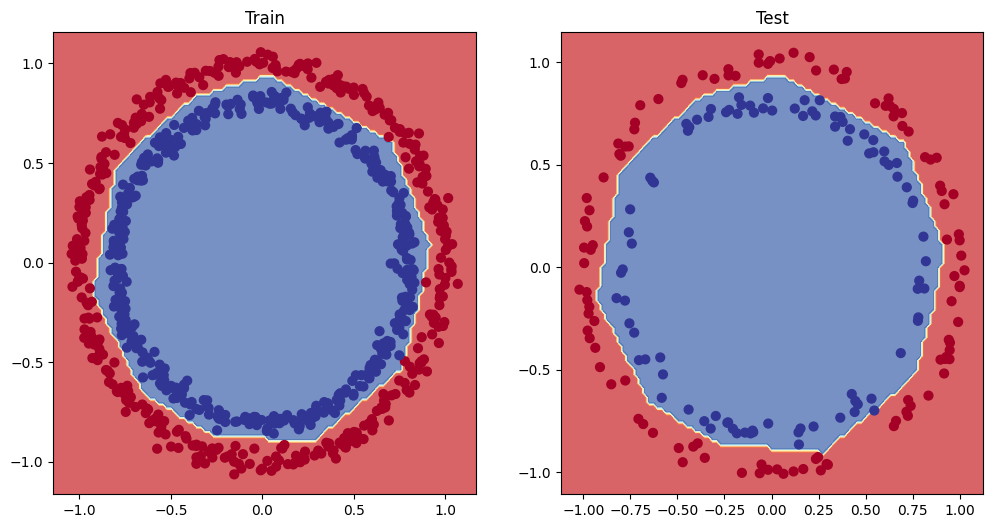

In [173]:
# Plot decision boundaries
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)

## 7.Replicating non-linear activation functions  

Neural networks, rather than us telling the model what to learn, we give it the tools to discover patterns in data and it tries to figure out the patterns on its own.  

And these tools are linear & non-linear activation functions

In [174]:
# Create a tensor
A = torch.arange(-10, 10, 1, dtype=torch.float32)
A.dtype

torch.float32

In [175]:
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

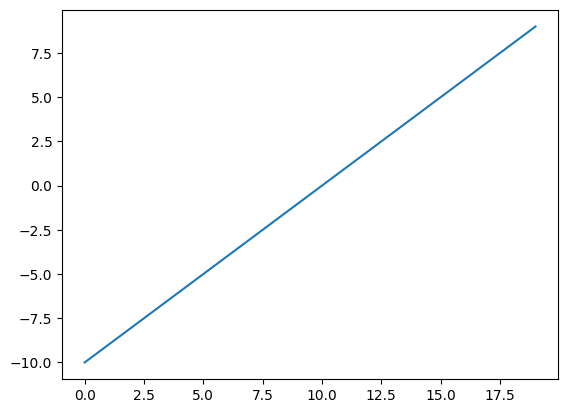

In [176]:
# Visualize the tensor
plt.plot(A)

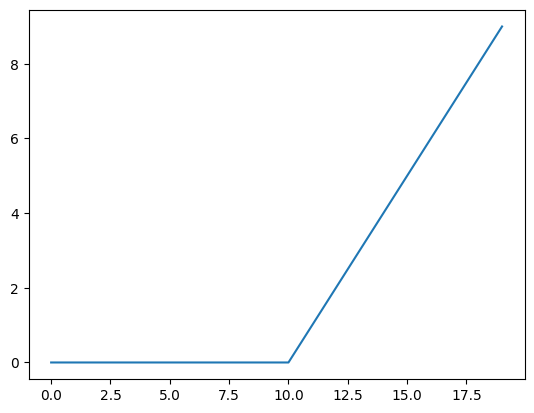

In [177]:
plt.plot(torch.relu(A))

In [178]:
def relu(x: torch.Tensor) -> torch.Tensor:
  return torch.maximum(torch.tensor(0), x) # inputs must be tensors

relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

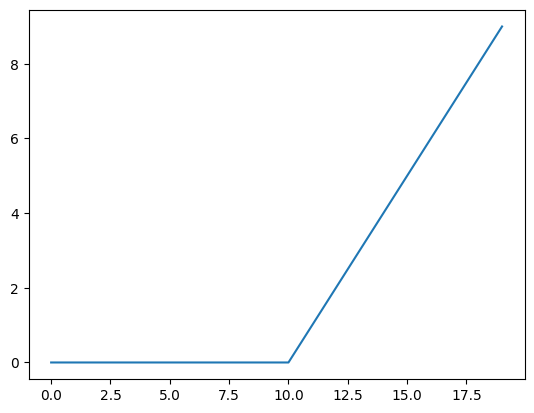

In [179]:
plt.plot(torch.relu(A))

In [180]:
# Now let's do the same for Sigmoid - https://docs.pytorch.org/docs/2.14/generated/torch.nn.Sigmoid.html
def sigmoid(x):
  return 1 / (1 + torch.exp(-x))

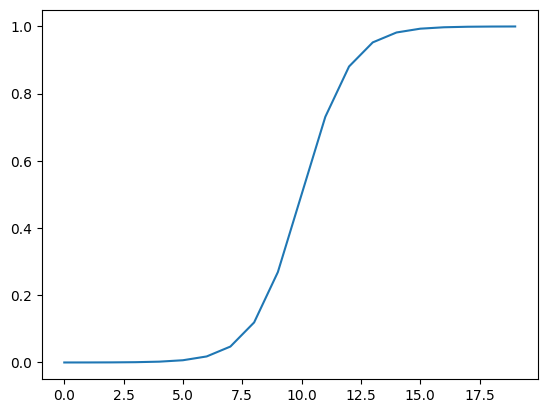

In [181]:
plt.plot(sigmoid(A))

## 8.Putting it all together with a multi-class classification problem  

- Binary classification = one thing or another (cat vs. dog, spam vs. not spam, fraud vs. not fraud)

- Multi-class classification = more than one thing or another(cat vs. dog vs. chicken)

### 8.1 Creating a toy multi-class dataset

You can use `make_blobs` function in `sklearn.datasets` to generate multi-class data samples - https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html

In [182]:
"""
# Import dependencies
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters for data creation
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

# 1. Create multi-class data
X_blob, y_blob = make_blobs(
    n_samples=1000,
    n_features=NUM_FEATURES,
    centers=NUM_CLASSES,
    cluster_std=1.5,
    random_state=RANDOM_SEED
)

# 2. Turn data into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.long)

# 3. Split into train and test
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(
    X_blob,
    y_blob,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# 4. Plot data (visualize, visualize, visualize)
plt.figure(figsize=(10,7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu);
"""



'\n# Import dependencies\nimport torch\nimport matplotlib.pyplot as plt\nfrom sklearn.datasets import make_blobs\nfrom sklearn.model_selection import train_test_split\n\n# Set the hyperparameters for data creation\nNUM_CLASSES = 4\nNUM_FEATURES = 2\nRANDOM_SEED = 42\n\n# 1. Create multi-class data\nX_blob, y_blob = make_blobs(\n    n_samples=1000,\n    n_features=NUM_FEATURES,\n    centers=NUM_CLASSES,\n    cluster_std=1.5,\n    random_state=RANDOM_SEED\n)\n\n# 2. Turn data into tensors\nX_blob = torch.from_numpy(X_blob).type(torch.float)\ny_blob = torch.from_numpy(y_blob).type(torch.long)\n\n# 3. Split into train and test\nX_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(\n    X_blob,\n    y_blob,\n    test_size=0.2,\n    random_state=RANDOM_SEED\n)\n\n# 4. Plot data (visualize, visualize, visualize)\nplt.figure(figsize=(10,7))\nplt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu);\n'

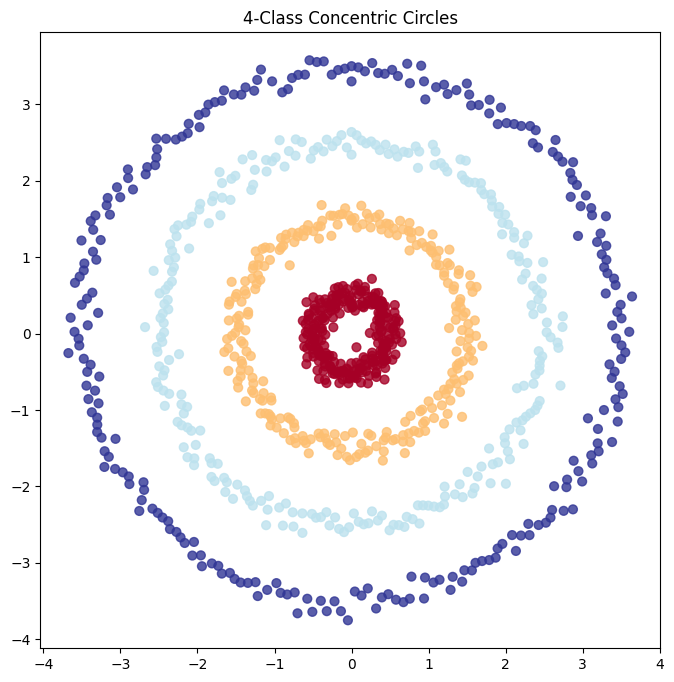

In [183]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# generate concentirc rings' data
N = 250 # The number of points of each concentric rings
K = 4   # 4 type
n_samples = N * K
X_circles = np.zeros((n_samples, 2))
y_circles = np.zeros(n_samples, dtype='uint8')

for j in range(K):
    ix = range(N*j, N*(j+1))
    r = j + 0.5 + np.random.randn(N) * 0.1
    t = np.linspace(0, 2*np.pi, N)

    X_circles[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
    y_circles[ix] = j

# Transfer dataset to tensor
X_blob = torch.from_numpy(X_circles).type(torch.float)
y_blob = torch.from_numpy(y_circles).type(torch.long)

# Split into training set and test set
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(
    X_blob,
    y_blob,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# Visualization
plt.figure(figsize=(8, 8))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu, s=40, alpha=0.8)
plt.title("4-Class Concentric Circles")
plt.show()

### 8.2 Building a multi-class classififcation model in PyTorch

In [184]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [185]:
# Build a multi-class classification model
class BlobModel(nn.Module):
  def __init__(self, input_features: int, output_features: int, Non_linear: type[nn.Module], hidden_units=8):
    """Initializes multi-class classification model.

    Args:
      input_features (int): Number of input features to the model
      output_features (int): Number of outputs features (number of output classes)
      hidden_units (int): Number of hidden units between layers, default 8
      Non_linear (nn.Module): Type of nonlinear layer (e.g. Non_linear=nn.ReLU)

    Returns:

    Examples:
    """
    super().__init__()
    self.linear_layer_stack = nn.Sequential(
        nn.Linear(in_features=input_features, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=output_features)
    )

  def forward(self, x):
    return self.linear_layer_stack(x)

# Create an instance of BlobModel and send it to the target device
model_4 = BlobModel(
    input_features=2,
    output_features=4,
    Non_linear=nn.ReLU,
    hidden_units=256
)

model_4


BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=4, bias=True)
  )
)

### 8.3 Create a loss function and an optimizer

In [186]:
# Create a loss function for multi-class classification
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params=model_4.parameters(),
    lr=0.01
)

### 8.4 Getting prediction probabilities for a multi-class PyTorch model  

In order to evaluate and train and test our model, we need to convert our model's outputs (logits) to prediction probabilities and then to prediction labels.  

`logits` (raw output of the model)->`probabilities` (use `torch.softmax`)->`Pred labels` (take the argmax of the prediction probabilities)

In [187]:
# Let's get some raw outputs of our model (logits)
model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test.to(device))
  print(y_logits[:20])

tensor([[ 0.0169, -0.0474, -0.0256,  0.0686],
        [ 0.0260, -0.0240, -0.0195,  0.0810],
        [ 0.0278, -0.0288, -0.0167,  0.0778],
        [ 0.1156,  0.0379,  0.0066,  0.1030],
        [ 0.0705,  0.0235,  0.0306,  0.0719],
        [ 0.0971,  0.0137,  0.0156,  0.1045],
        [ 0.0534,  0.0411,  0.0269,  0.0801],
        [ 0.0218, -0.0534, -0.0276,  0.0805],
        [ 0.0777,  0.0092,  0.0005,  0.0777],
        [ 0.0390,  0.0162,  0.0450,  0.0238],
        [ 0.0196, -0.0253, -0.0565,  0.0291],
        [ 0.0359,  0.0009,  0.0274,  0.0082],
        [ 0.0746,  0.0542,  0.0205,  0.0981],
        [ 0.0276,  0.0232, -0.0399,  0.1307],
        [ 0.0941,  0.0045,  0.0203,  0.1286],
        [ 0.1416,  0.0577, -0.0212,  0.1524],
        [ 0.0208, -0.0165, -0.0070,  0.0307],
        [ 0.0768,  0.0564,  0.0087,  0.1278],
        [ 0.0202, -0.0786, -0.0619,  0.1085],
        [ 0.0182,  0.0054,  0.0053,  0.0214]])


In [188]:
# Convert our model's logit outputs to prediction probabilities
y_pred_probs = torch.softmax(y_logits,dim=1)
print(y_logits[:5])
print(y_pred_probs[:5])

tensor([[ 0.0169, -0.0474, -0.0256,  0.0686],
        [ 0.0260, -0.0240, -0.0195,  0.0810],
        [ 0.0278, -0.0288, -0.0167,  0.0778],
        [ 0.1156,  0.0379,  0.0066,  0.1030],
        [ 0.0705,  0.0235,  0.0306,  0.0719]])
tensor([[0.2532, 0.2374, 0.2427, 0.2667],
        [0.2523, 0.2400, 0.2411, 0.2666],
        [0.2530, 0.2391, 0.2420, 0.2660],
        [0.2625, 0.2429, 0.2354, 0.2592],
        [0.2553, 0.2436, 0.2454, 0.2557]])


In [189]:
# Convert our model's prediction probabilities to prediction labels
y_preds = torch.argmax(y_pred_probs, dim=1)
y_preds[:20]

tensor([3, 3, 3, 0, 3, 3, 3, 3, 3, 2, 3, 0, 3, 3, 3, 3, 3, 3, 3, 3])

In [190]:
y_blob_test[:20]

tensor([2, 2, 2, 2, 1, 2, 2, 2, 3, 0, 3, 0, 2, 3, 3, 3, 1, 3, 3, 1])

### 8.5 Creating a training loop and testing loop for a multi-class PyTorch model

In [191]:
# Fit the multi-class model to the data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
epochs = 100

# Put data to the target device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

# Loop through data
for epoch in range(epochs):
  model_4.train()
  y_logits = model_4(X_blob_train)
  y_prob = torch.softmax(y_logits, dim=1).argmax(dim=1)
  train_loss = loss_fn(y_logits, y_blob_train)
  train_acc = accuracy_fn(
      y_true=y_blob_train,
      y_pred=y_prob
  )
  optimizer.zero_grad()
  train_loss.backward()
  optimizer.step()

  model_4.eval()
  with torch.inference_mode():
    # 1. forward pass
    test_logits = model_4(X_blob_test)
    test_prob = torch.softmax(test_logits, dim=1).argmax(dim=1)
    # 2. Calculate test loss and accuracy
    test_loss = loss_fn(test_logits, y_blob_test)
    test_acc = accuracy_fn(
        y_true=y_blob_test,
        y_pred=test_prob
    )

   # Print out what's happening
  if epoch % 10 == 0:
      print(f"Epoch: {epoch} | Loss: {train_loss:.5f}, Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 1.37899, Train Acc: 41.25% | Test Loss: 2.01668, Test Acc: 24.50%
Epoch: 10 | Loss: 0.46693, Train Acc: 84.38% | Test Loss: 0.38152, Test Acc: 86.00%
Epoch: 20 | Loss: 0.01427, Train Acc: 100.00% | Test Loss: 0.02310, Test Acc: 100.00%
Epoch: 30 | Loss: 0.00427, Train Acc: 99.88% | Test Loss: 0.00216, Test Acc: 100.00%
Epoch: 40 | Loss: 0.00017, Train Acc: 100.00% | Test Loss: 0.00109, Test Acc: 100.00%
Epoch: 50 | Loss: 0.00015, Train Acc: 100.00% | Test Loss: 0.00049, Test Acc: 100.00%
Epoch: 60 | Loss: 0.00005, Train Acc: 100.00% | Test Loss: 0.00027, Test Acc: 100.00%
Epoch: 70 | Loss: 0.00003, Train Acc: 100.00% | Test Loss: 0.00013, Test Acc: 100.00%
Epoch: 80 | Loss: 0.00002, Train Acc: 100.00% | Test Loss: 0.00006, Test Acc: 100.00%
Epoch: 90 | Loss: 0.00002, Train Acc: 100.00% | Test Loss: 0.00005, Test Acc: 100.00%


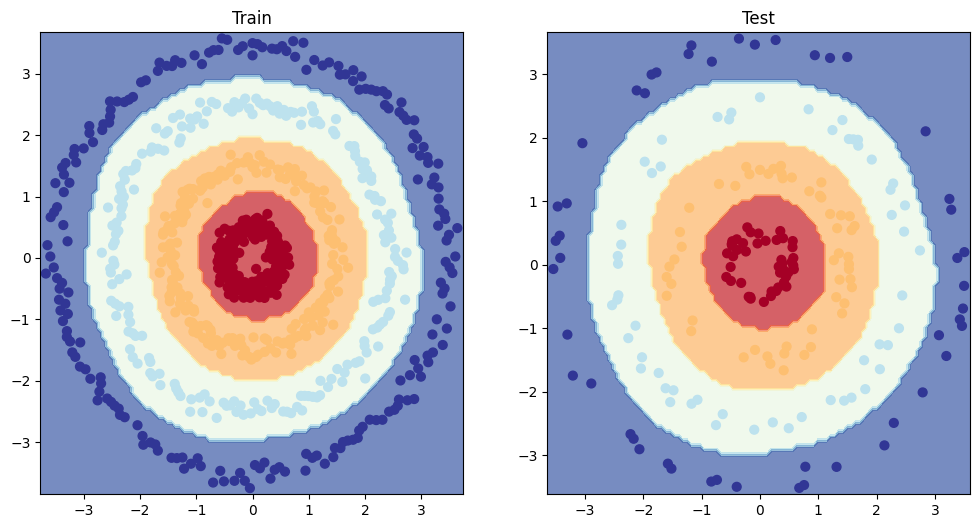

In [192]:
from helper_function import plot_decision_boundary
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)
plt.show()

In [197]:
model_4.eval()
with torch.inference_mode():
  test_logits = model_4(X_blob_test)
  test_labels = torch.softmax(test_logits, dim=1).argmax(dim=1)

## 9. A few more classification metircs... (to evaluate our classification model)

- Accuracy - out of 100 samples, how many does our model get right?  
- Precision
- Recall
- F1-score
- Confusion matrix
- Classification report  

See this article for when to use precision/recall - https://willkoehrsen.github.io/statistics/learning/beyond-accuracy-precision-and-recall/  

Precision and Recall tradeoff - https://spotintelligence.com/2024/09/11/precision-and-recall/  

If you want to access to a lot of PyTorch metrics, see `TorchMetrics` - https://blog.csdn.net/qq_33431368/article/details/115922461

In [198]:
!pip install torchmetrics

In [200]:
from torchmetrics import Accuracy

# Setup metric
torchmetric_accuracy = Accuracy(task="multiclass", num_classes=4).to(device)

# Calculate accuracy
torchmetric_accuracy.reset()
torchmetric_accuracy(test_labels, y_blob_test)

tensor(1.)